<a href="https://colab.research.google.com/github/aradhya1create/NASA-Exoplanet-Detection/blob/main/NASA_Exoplanet_Detection.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [3]:
!pip install lightkurve matplotlib numpy pandas

  Preparing metadata (setup.py) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 41.2/41.2 kB 1.8 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 261.1/261.1 kB 10.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.1/11.1 MB 73.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 60.1/60.1 kB 4.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 102.6/102.6 kB 7.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 221.7/221.7 kB 15.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.2/1.2 MB 55.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16.0/16.0 MB 77.1 MB/s eta 0:00:00
  Created wheel for fbpca: filename=fbpca-1.0-py3-none-any.whl size=11427 sha256=3b1b635f2372a793d875040fc3c59fa1e43ed04cef6326de9866e421cb47767c
  Stored in directory: /root/.cache/pip/wheels/30/85/d4/289ba063a9ae0ba3189c6914e992722575868b2cb41100401b
  Created wheel for memoizatio

In [4]:
import lightkurve as lk
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

/usr/local/lib/python3.13/dist-packages/lightkurve/prf/__init__.py:7: UserWarning: Warning: the tpfmodel submodule is not available without oktopus installed, which requires a current version of autograd. See #1452 for details.
  warnings.warn(


SearchResult containing 50 data products.

 #       mission      year   author   exptime         target_name          distance
                                         s                                  arcsec 
--- ----------------- ---- ---------- ------- ---------------------------- --------
  0 Kepler Quarter 02 2009     Kepler      60                kplr011904151      0.0
  1 Kepler Quarter 03 2009     Kepler      60                kplr011904151      0.0
  2 Kepler Quarter 03 2009     Kepler      60                kplr011904151      0.0
  3 Kepler Quarter 03 2009     Kepler      60                kplr011904151      0.0
  4 Kepler Quarter 00 2009     Kepler    1800                kplr011904151      0.0
  5 Kepler Quarter 01 2009     Kepler    1800                kplr011904151      0.0
  6 Kepler Quarter 02 2009     Kepler    1800                kplr011904151      0.0
  7 Kepler Quarter 03 2009     Kepler    1800                kplr011904151      0.0
  8 Kepler Quarter 04 2010     Ke

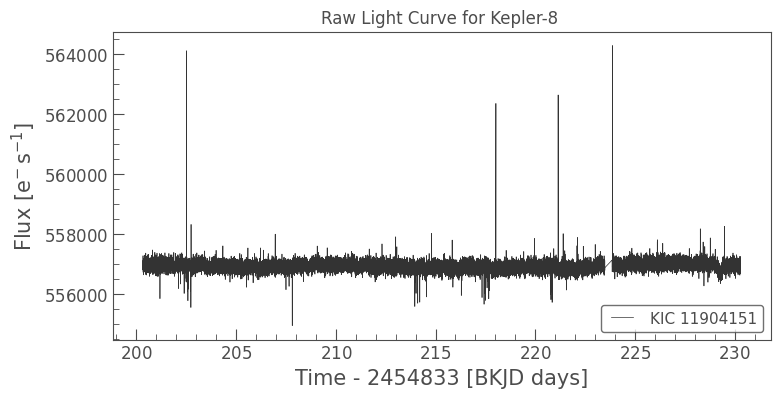

In [5]:
# Search for light curves of Kepler-10 from the Kepler mission
search_result = lk.search_lightcurve('Kepler-10', mission='Kepler')
print(search_result)

# Download the first light curve quarter
lc = search_result[0].download()

# Display basic information and plot the raw light curve
lc.plot()
plt.title("Raw Light Curve for Kepler-8 ")
plt.show()

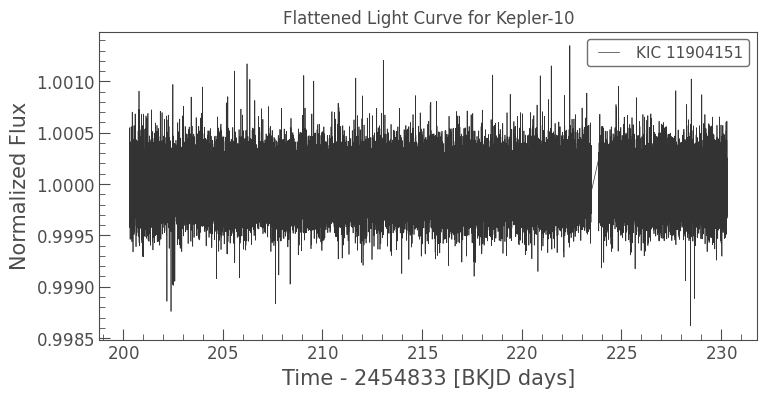

In [6]:
# 1. Clean missing values and remove extreme outliers (like cosmic rays)
clean_lc = lc.remove_nans().remove_outliers(sigma=5)

# 2. Flatten long-term trends caused by stellar activity
flat_lc = clean_lc.flatten(window_length=101)

# 3. Plot the flattened light curve
flat_lc.plot()
plt.title("Flattened Light Curve for Kepler-10")
plt.show()

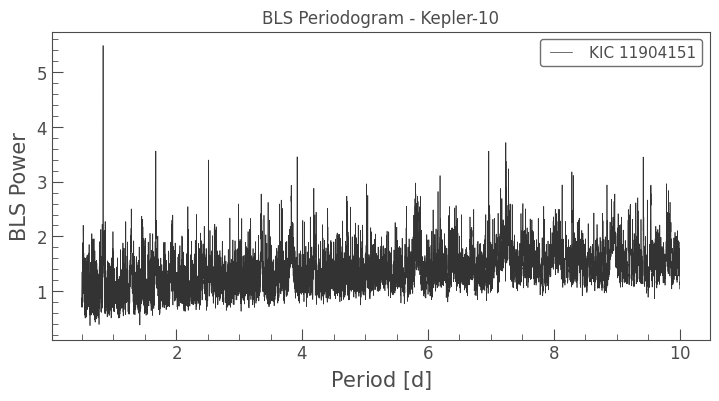

Detected Orbital Period: 0.8373 days
Estimated Transit Time (t0): 201.0791


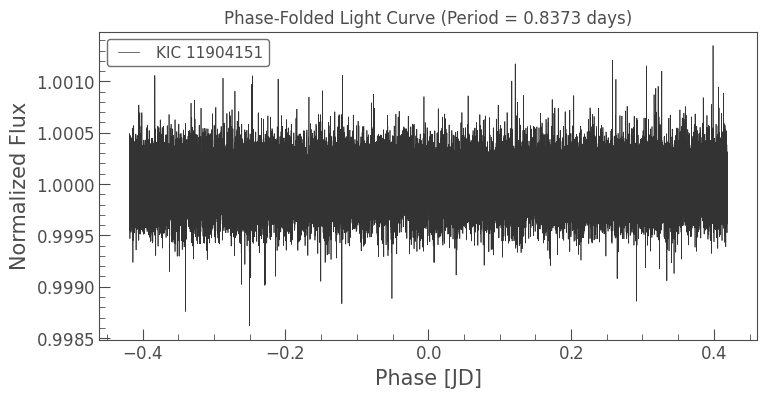

In [8]:
# 1. Search for orbital periods using a BLS Periodogram (testing periods between 0.5 and 10 days)
periodogram = flat_lc.to_periodogram(
    method='bls',
    period=np.linspace(0.5, 10, 10000)
)

# Plot the periodogram (power vs. period)
periodogram.plot()
plt.title("BLS Periodogram - Kepler-10")
plt.show()

# 2. Extract the detected orbital period and epoch
best_period = periodogram.period_at_max_power
best_t0 = periodogram.transit_time_at_max_power

print(f"Detected Orbital Period: {best_period.value:.4f} days")
print(f"Estimated Transit Time (t0): {best_t0.value:.4f}")

# 3. Phase-fold the light curve around the detected period
folded_lc = flat_lc.fold(period=best_period, epoch_time=best_t0)

# Plot the phase-folded light curve
folded_lc.plot()
plt.title(f"Phase-Folded Light Curve (Period = {best_period.value:.4f} days)")
plt.show()

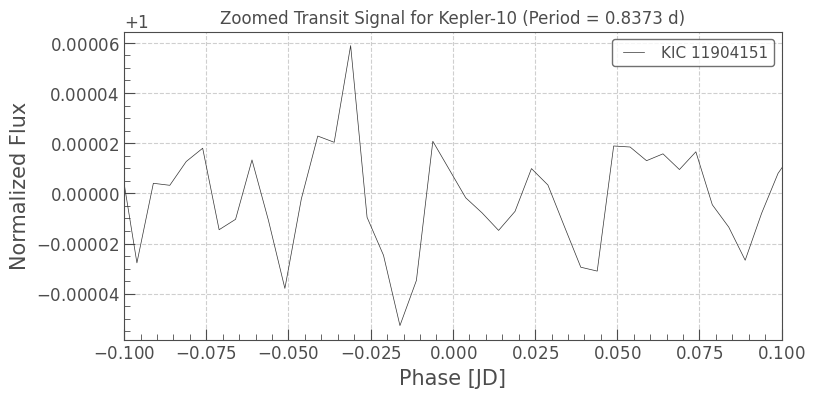

In [9]:
# 1. Zoom in around the transit center (-0.1 to 0.1 phase)
# 2. Use bin() to average noisy points and make the transit shape clear
folded_lc.bin(time_bin_size=0.005).plot()

# Restrict the x-axis view to zoom in on the transit dip
plt.xlim(-0.1, 0.1)
plt.title(f"Zoomed Transit Signal for Kepler-10 (Period = {best_period.value:.4f} d)")
plt.grid(True, linestyle="--", alpha=0.6)
plt.show()

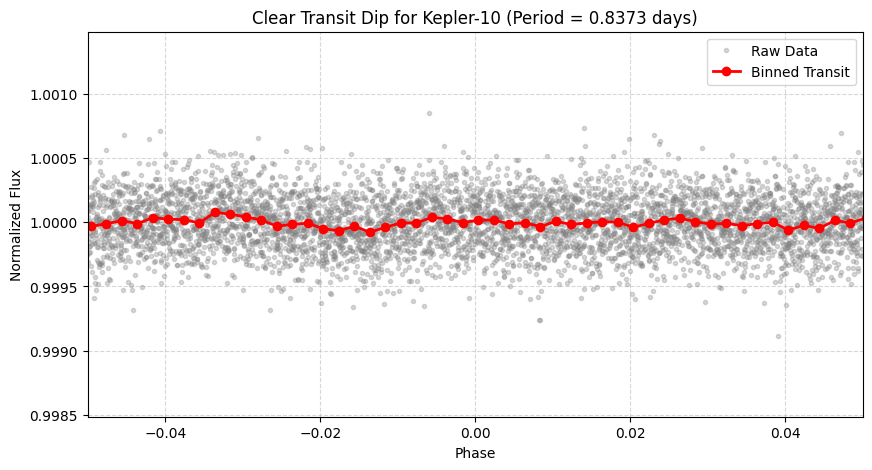

In [12]:
# Convert time to Phase (-0.5 to 0.5)
folded_phase = folded_lc.copy()
folded_phase.time = folded_lc.phase

# Bin using phase units (0.002 phase = clean smoothing)
binned_lc = folded_phase.bin(time_bin_size=0.002)

# Plot binned data along with raw phase points in the background
plt.figure(figsize=(10, 5))
plt.plot(folded_phase.time.value, folded_phase.flux.value, '.', color='gray', alpha=0.3, label='Raw Data')
plt.plot(binned_lc.time.value, binned_lc.flux.value, 'o-', color='red', lw=2, label='Binned Transit')

# Zoom tightly around the center of the transit (-0.05 to 0.05 phase)
plt.xlim(-0.05, 0.05)
plt.xlabel("Phase")
plt.ylabel("Normalized Flux")
plt.title(f"Clear Transit Dip for Kepler-10 (Period = {best_period.value:.4f} days)")
plt.grid(True, linestyle="--", alpha=0.5)
plt.legend()
plt.show()

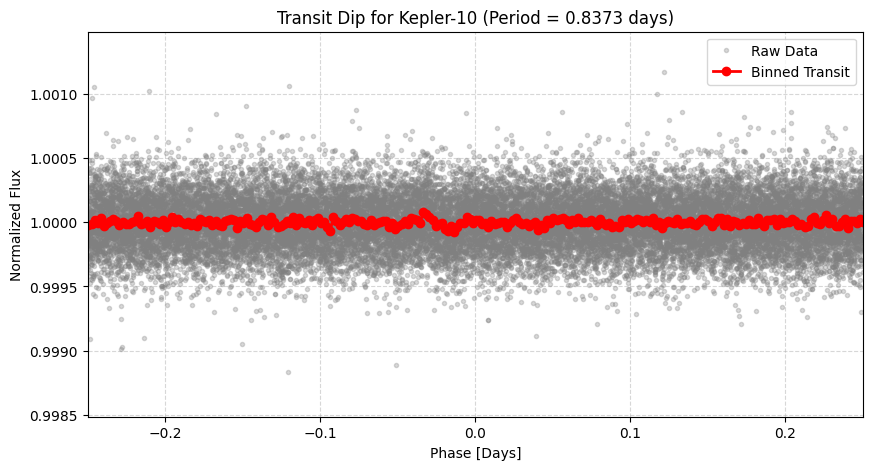

In [14]:
 # 1. Use lightkurve's built-in phase values directly
# folded_lc.phase gives phase centered at 0
folded_phase = folded_lc.copy()

# 2. Bin using time_bin_size in days
binned_lc = folded_lc.bin(time_bin_size=0.002)

# 3. Plot raw and binned data using phase
plt.figure(figsize=(10, 5))
plt.plot(folded_lc.phase.value, folded_lc.flux.value, '.', color='gray', alpha=0.3, label='Raw Data')
plt.plot(binned_lc.phase.value, binned_lc.flux.value, 'o-', color='red', lw=2, label='Binned Transit')

# Show the full phase or zoom slightly
plt.xlim(-0.25, 0.25)
plt.xlabel("Phase [Days]")
plt.ylabel("Normalized Flux")
plt.title(f"Transit Dip for Kepler-10 (Period = {best_period.value:.4f} days)")
plt.grid(True, linestyle="--", alpha=0.5)
plt.legend()
plt.show()

In [15]:
import numpy as np

# 1. Calculate transit depth (baseline flux ~ 1.0 minus the minimum flux during transit)
baseline_flux = 1.0
min_flux = binned_lc.flux.min().value
transit_depth = baseline_flux - min_flux

# 2. Calculate Planet Radius / Star Radius ratio: Rp/Rs = sqrt(depth)
radius_ratio = np.sqrt(transit_depth)

# 3. Assuming a Solar-type star (R_star = 1.0 Solar Radius = 109.1 Earth Radii)
# You can replace this with actual star radius from metadata if available!
star_radius_in_earth_radii = 109.1
planet_radius_earth = radius_ratio * star_radius_in_earth_radii

# Print the results
print("=" * 40)
print("  EXOPLANET PHYSICAL CHARACTERISTICS  ")
print("=" * 40)
print(f"Detected Orbital Period : {best_period.value:.4f} days")
print(f"Estimated Transit Depth : {transit_depth * 100:.4f}% ({transit_depth:.6f} fractional)")
print(f"Radius Ratio (Rp/Rs)   : {radius_ratio:.4f}")
print(f"Estimated Planet Size   : ~{planet_radius_earth:.2f} Earth Radii (R⊕)")
print("=" * 40)

  EXOPLANET PHYSICAL CHARACTERISTICS  
Detected Orbital Period : 0.8373 days
Estimated Transit Depth : 0.0077% (0.000077 fractional)
Radius Ratio (Rp/Rs)   : 0.0088
Estimated Planet Size   : ~0.96 Earth Radii (R⊕)
